In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Matplotlib is building the font cache; this may take a moment.


In [10]:
rng = np.random.default_rng(42)
n = 5000

df = pd.DataFrame({
    "experience_years": rng.uniform(0, 10, n),
    "gpa": rng.uniform(2.0, 4.0, n),
    "study_hours": rng.uniform(5, 40, n),
    "projects_completed": rng.integers(0, 15, n),
    "certifications": rng.integers(0, 6, n),
})

df["salary"] = (
    15000
    + 2500 * df["experience_years"]
    + 4000 * df["gpa"]
    + 150 * df["study_hours"]
    + 600 * df["projects_completed"]
    + 1200 * df["certifications"]
    + rng.normal(0, 3000, n)
)

output_path = Path.home() / "regression_data.csv"
df.to_csv(output_path, index=False)
print(f"Saved to: {output_path}")
df.head()

Saved to: C:\Users\Eben\regression_data.csv


,experience_years,gpa,study_hours,projects_completed,certifications,salary
0,7.739560,2.436298,30.225494,3,5,50950.602175
1,4.388784,3.325855,29.893322,5,2,47975.315695
2,8.585979,3.533723,12.094326,12,4,59168.786277
3,6.973680,2.333272,6.282939,1,5,55434.347048
4,0.941773,2.087717,15.632983,1,0,29287.721105


In [3]:
X = df.drop(columns="salary")
y = df["salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(X_train.shape, X_test.shape)

(4000, 5) (1000, 5)


In [4]:
# Simple Linear Regression: one feature
slr = LinearRegression()
slr.fit(X_train[["experience_years"]], y_train)
slr_pred = slr.predict(X_test[["experience_years"]])

# Multiple Linear Regression: all features
mlr = LinearRegression()
mlr.fit(X_train, y_train)
mlr_pred = mlr.predict(X_test)

In [5]:
def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred),
    }

results = pd.DataFrame([
    evaluate("SLR", y_test, slr_pred),
    evaluate("MLR", y_test, mlr_pred),
])
results

,Model,MAE,MSE,RMSE,R2
0,SLR,4157.151621,2.625731e+07,5124.188587,0.678502
1,MLR,2332.643499,8.769983e+06,2961.415711,0.892619


,Sample,Actual,SLR Predicted,SLR Residual,MLR Predicted,MLR Residual
0,1,58362.26,62110.34,-3748.09,54551.35,3810.91
1,2,41407.20,45910.22,-4503.02,43496.73,-2089.53
2,3,53321.60,56522.37,-3200.77,54846.95,-1525.35
3,4,56338.10,54715.57,1622.53,52840.58,3497.52
4,5,52060.83,51785.94,274.89,53161.44,-1100.62
5,6,46010.70,48885.26,-2874.56,47282.89,-1272.20
6,7,41507.35,37902.71,3604.64,44853.93,-3346.57
7,8,54086.79,52558.74,1528.06,51557.81,2528.98
8,9,60549.95,51163.73,9386.22,58864.43,1685.51
9,10,63314.08,60886.68,2427.41,62818.53,495.55


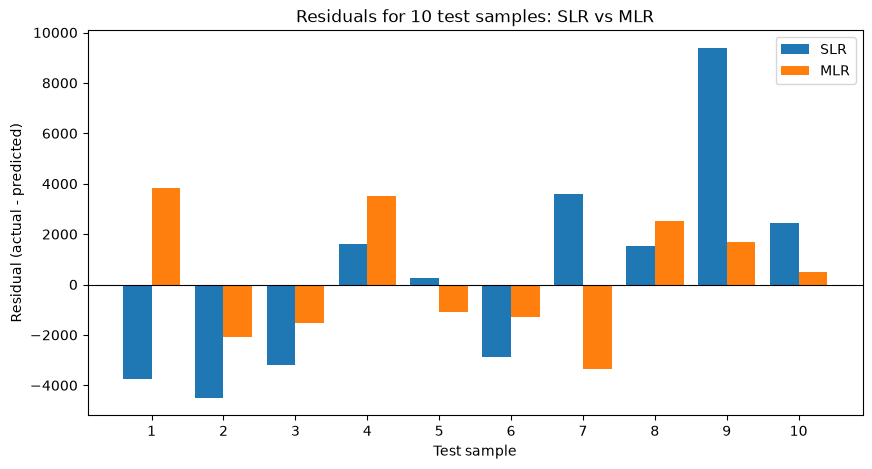

In [6]:
y_actual = y_test.iloc[:10].values
res_slr = y_actual - slr_pred[:10]
res_mlr = y_actual - mlr_pred[:10]

residuals = pd.DataFrame({
    "Sample": range(1, 11),
    "Actual": y_actual,
    "SLR Predicted": slr_pred[:10],
    "SLR Residual": res_slr,
    "MLR Predicted": mlr_pred[:10],
    "MLR Residual": res_mlr,
})
display(residuals.round(2))

x = np.arange(10)
plt.figure(figsize=(10, 5))
plt.bar(x - 0.2, res_slr, width=0.4, label="SLR")
plt.bar(x + 0.2, res_mlr, width=0.4, label="MLR")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(x, range(1, 11))
plt.xlabel("Test sample")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residuals for 10 test samples: SLR vs MLR")
plt.legend()
plt.show()